In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import warnings 
warnings.filterwarnings('ignore')

In [2]:
data = pd.read_csv(r"C:\Users\User\OneDrive\Desktop\Crop_Recommendation.csv")

In [3]:
data.head()

,Nitrogen,Phosphorus,Potassium,Temperature,Humidity,pH_Value,Rainfall,Crop
0,90,42,43,20.879744,82.002744,6.502985,202.935536,Rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,Rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,Rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,Rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,Rice


In [4]:
data.tail()

,Nitrogen,Phosphorus,Potassium,Temperature,Humidity,pH_Value,Rainfall,Crop
2195,107,34,32,26.774637,66.413269,6.780064,177.774507,Coffee
2196,99,15,27,27.417112,56.636362,6.086922,127.924610,Coffee
2197,118,33,30,24.131797,67.225123,6.362608,173.322839,Coffee
2198,117,32,34,26.272418,52.127394,6.758793,127.175293,Coffee
2199,104,18,30,23.603016,60.396475,6.779833,140.937041,Coffee


In [5]:
data.isna().any()

Nitrogen       False
Phosphorus     False
Potassium      False
Temperature    False
Humidity       False
pH_Value       False
Rainfall       False
Crop           False
dtype: bool

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Nitrogen     2200 non-null   int64  
 1   Phosphorus   2200 non-null   int64  
 2   Potassium    2200 non-null   int64  
 3   Temperature  2200 non-null   float64
 4   Humidity     2200 non-null   float64
 5   pH_Value     2200 non-null   float64
 6   Rainfall     2200 non-null   float64
 7   Crop         2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [7]:
data.duplicated().any()

np.False_

In [8]:
data.describe()

,Nitrogen,Phosphorus,Potassium,Temperature,Humidity,pH_Value,Rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


## Visualising data by matplotlib

In [9]:
data1 = data.drop(['Nitrogen', 'Phosphorus', 'Potassium', 'Temperature', 'Humidity', 'pH_Value', 'Rainfall'], axis = 1)
data1

,Crop
0,Rice
1,Rice
2,Rice
3,Rice
4,Rice
...,...
2195,Coffee
2196,Coffee
2197,Coffee
2198,Coffee


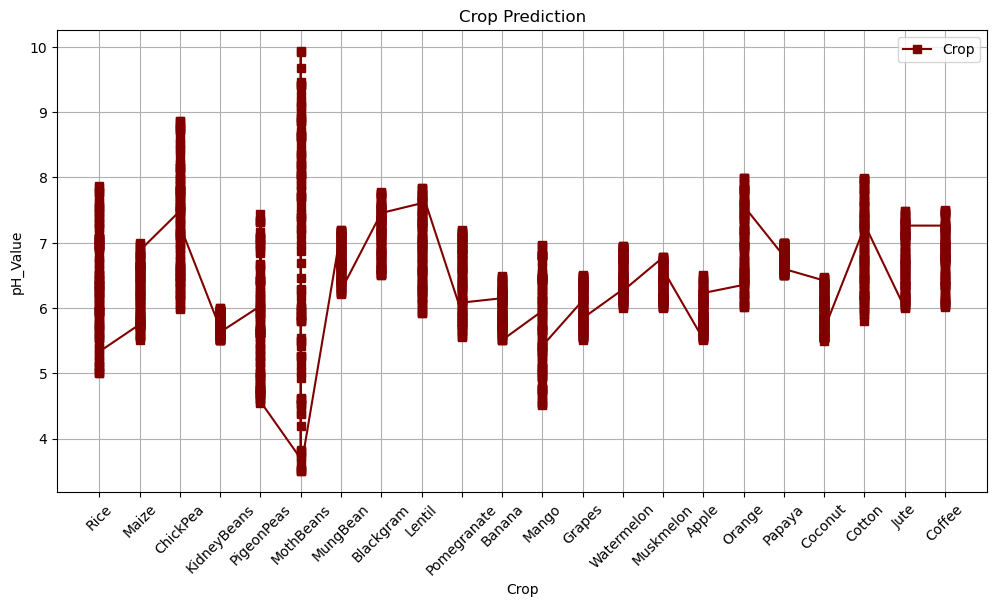

In [10]:
plt.figure(figsize = (12,6))
plt.plot(data['Crop'], data['pH_Value'],color = '#800000', label = 'Crop', marker = 's')
plt.xlabel('Crop')
plt.ylabel('pH_Value')
plt.title('Crop Prediction')
plt.legend()
plt.grid(True)
plt.xticks(rotation = 45)
plt.show()

## Setting Target Value

In [11]:
x = data.drop(['Crop'],axis = 1)
y = data['Crop']

In [12]:
x

,Nitrogen,Phosphorus,Potassium,Temperature,Humidity,pH_Value,Rainfall
0,90,42,43,20.879744,82.002744,6.502985,202.935536
1,85,58,41,21.770462,80.319644,7.038096,226.655537
2,60,55,44,23.004459,82.320763,7.840207,263.964248
3,74,35,40,26.491096,80.158363,6.980401,242.864034
4,78,42,42,20.130175,81.604873,7.628473,262.717340
...,...,...,...,...,...,...,...
2195,107,34,32,26.774637,66.413269,6.780064,177.774507
2196,99,15,27,27.417112,56.636362,6.086922,127.924610
2197,118,33,30,24.131797,67.225123,6.362608,173.322839
2198,117,32,34,26.272418,52.127394,6.758793,127.175293


In [13]:
y

0         Rice
1         Rice
2         Rice
3         Rice
4         Rice
         ...  
2195    Coffee
2196    Coffee
2197    Coffee
2198    Coffee
2199    Coffee
Name: Crop, Length: 2200, dtype: object

In [14]:
xtrain,xtest,ytrain,ytest = train_test_split(x,y,test_size = 0.3,random_state = 42)

In [15]:
ytrain

1102     Mango
1159     Mango
141      Maize
1004    Banana
2         Rice
         ...  
1638    Orange
1095    Banana
1130     Mango
1294    Grapes
860     Lentil
Name: Crop, Length: 1540, dtype: object

In [16]:
xtrain

,Nitrogen,Phosphorus,Potassium,Temperature,Humidity,pH_Value,Rainfall
1102,21,26,27,27.003155,47.675254,5.699587,95.851183
1159,29,35,28,28.347161,53.539031,6.967418,90.402604
141,60,44,23,24.794708,70.045567,5.722580,76.728601
1004,80,77,49,26.054330,79.396545,5.519088,113.229737
2,60,55,44,23.004459,82.320763,7.840207,263.964248
...,...,...,...,...,...,...,...
1638,10,5,5,21.213070,91.353492,7.817846,112.983436
1095,108,94,47,27.359116,84.546250,6.387431,90.812505
1130,11,36,31,27.920633,51.779659,6.475449,100.258567
1294,11,124,204,13.429886,80.066340,6.361141,71.400430


# Model Fitting

## Logistic regression

In [17]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()


In [18]:
model.fit(xtrain, ytrain)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [19]:
poi = model.predict(xtest)
poi

array(['Muskmelon', 'Watermelon', 'Papaya', 'Papaya', 'Apple', 'Mango',
       'Apple', 'MothBeans', 'MungBean', 'Lentil', 'Blackgram', 'Coconut',
       'Pomegranate', 'Jute', 'Coconut', 'Pomegranate', 'Apple', 'Cotton',
       'Papaya', 'Muskmelon', 'Coffee', 'Papaya', 'Orange', 'Papaya',
       'ChickPea', 'Jute', 'MungBean', 'Orange', 'PigeonPeas', 'Rice',
       'Pomegranate', 'MothBeans', 'Jute', 'Lentil', 'Jute', 'Blackgram',
       'Jute', 'ChickPea', 'ChickPea', 'KidneyBeans', 'Papaya', 'Mango',
       'Blackgram', 'Maize', 'MungBean', 'Maize', 'PigeonPeas', 'Coconut',
       'Muskmelon', 'Maize', 'Blackgram', 'Coffee', 'Grapes', 'MungBean',
       'Coffee', 'KidneyBeans', 'Cotton', 'Apple', 'Banana', 'Lentil',
       'Watermelon', 'Coconut', 'Lentil', 'Orange', 'Papaya', 'Blackgram',
       'Orange', 'Rice', 'Muskmelon', 'PigeonPeas', 'Muskmelon',
       'Coconut', 'Jute', 'Banana', 'Blackgram', 'Papaya', 'Banana',
       'Cotton', 'Watermelon', 'Orange', 'Coffee', 'ChickPea'

In [20]:
Logistictrain = model.score(xtrain, ytrain)*100
Logistictrain

97.40259740259741

In [21]:
Logistictest = model.score(xtest,ytest)*100
Logistictest

94.6969696969697

## DecisionTreeClassifier

In [22]:
from sklearn.tree import DecisionTreeClassifier
model2  = DecisionTreeClassifier()

In [23]:
model2.fit(xtrain, ytrain)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [24]:
DecisionTreetrain = model2.score(xtrain,ytrain)*100
DecisionTreetrain 

100.0

In [25]:
DecisionTreetest = model2.score(xtest, ytest)*100
DecisionTreetest

98.33333333333333

## RandomForestClassifier

In [26]:
from sklearn.ensemble import RandomForestClassifier
model3 = RandomForestClassifier()
model3.fit(xtrain, ytrain)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [27]:
RandomForesttrain = model3.score(xtrain, ytrain)*100
RandomForesttrain

100.0

In [28]:
RandomForesttest = model3.score(xtest, ytest)*100
RandomForesttest

99.24242424242425

## AdaBoostClassifier

In [29]:
from sklearn.ensemble import AdaBoostClassifier
model4 = AdaBoostClassifier()
model4.fit(xtrain, ytrain)

,estimator,None
,n_estimators,50
,learning_rate,1.0
,algorithm,'deprecated'
,random_state,None


In [30]:
AdaBoosttrain = model4.score(xtrain, ytrain)*100
AdaBoosttrain

18.961038961038962

In [31]:
AdaBoosttest = model4.score(xtest, ytest)*100
AdaBoosttest

19.242424242424242

## GradientBoostingClassifier

In [32]:
from sklearn.ensemble import GradientBoostingClassifier
model5 = GradientBoostingClassifier()
model5.fit(xtrain, ytrain)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [33]:
GradientBoostingtrain = model5.score(xtrain, ytrain)*100
GradientBoostingtrain

100.0

In [34]:
GradientBoostingtest = model5.score(xtest, ytest)*100
GradientBoostingtest

98.33333333333333

## KNeighborsClassifier

In [35]:
from sklearn.neighbors import KNeighborsClassifier
model6 = KNeighborsClassifier()
model6.fit(xtrain, ytrain)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [36]:
Kneighborstrain = model.score(xtrain, ytrain)*100
Kneighborstrain

97.40259740259741

In [37]:
Kneighborstest = model.score(xtest, ytest)*100
Kneighborstest

94.6969696969697

## GaussianNB

In [38]:
from sklearn.naive_bayes import GaussianNB
model7 = GaussianNB()
model7.fit(xtrain, ytrain)

,priors,None
,var_smoothing,1e-09


In [39]:
Gaussiantrain = model7.score(xtrain, ytrain)*100
Gaussiantrain

99.54545454545455

In [40]:
Gaussiantest = model7.score(xtest, ytest)*100
Gaussiantest

99.39393939393939

## Prediction

In [41]:
Nitrogen = int(input("Enter the Nitrogen"))
Nitrogen

Enter the Nitrogen 25


25

In [42]:
Phosphorus = int(input("Enter the Phosphorus"))
Phosphorus

Enter the Phosphorus 27


27

In [43]:
Potassium = int(input("Enter the Potassium"))
Potassium

Enter the Potassium 27


27

In [44]:
Temperature = float(input("Enter the Temperature"))
Temperature

Enter the Temperature 30


30.0

In [45]:
Humidity = float(input("Enter the Humidity"))
Humidity

Enter the Humidity 47


47.0

In [46]:
pH_Value = float(input("Enter the pH_value"))
pH_Value

Enter the pH_value 7


7.0

In [47]:
Rainfall = float(input("Enter the Rainfall"))
Rainfall

Enter the Rainfall 50


50.0

In [48]:
print(model3.predict([[Nitrogen, Phosphorus, Potassium, Temperature, Humidity, pH_Value, Rainfall]]))

['Mango']


In [49]:
score = pd.DataFrame({'Model':['LogisticRegression', 'DecisionTreeClassifier', 'RandomForestClassifier', 'KNeighborsClassifier', 'AdaBoostClassifier', 'GradientBoostClassifier', 'GaussianNB'],
                     'TrainingScore':[Logistictrain, DecisionTreetrain, RandomForesttrain, Kneighborstrain, AdaBoosttrain, GradientBoostingtrain, Gaussiantrain],
                     'TestingScore':[Logistictest, DecisionTreetest, RandomForesttest, Kneighborstest, AdaBoosttest, GradientBoostingtest, Gaussiantest]})
score

,Model,TrainingScore,TestingScore
0,LogisticRegression,97.402597,94.696970
1,DecisionTreeClassifier,100.000000,98.333333
2,RandomForestClassifier,100.000000,99.242424
3,KNeighborsClassifier,97.402597,94.696970
4,AdaBoostClassifier,18.961039,19.242424
5,GradientBoostClassifier,100.000000,98.333333
6,GaussianNB,99.545455,99.393939


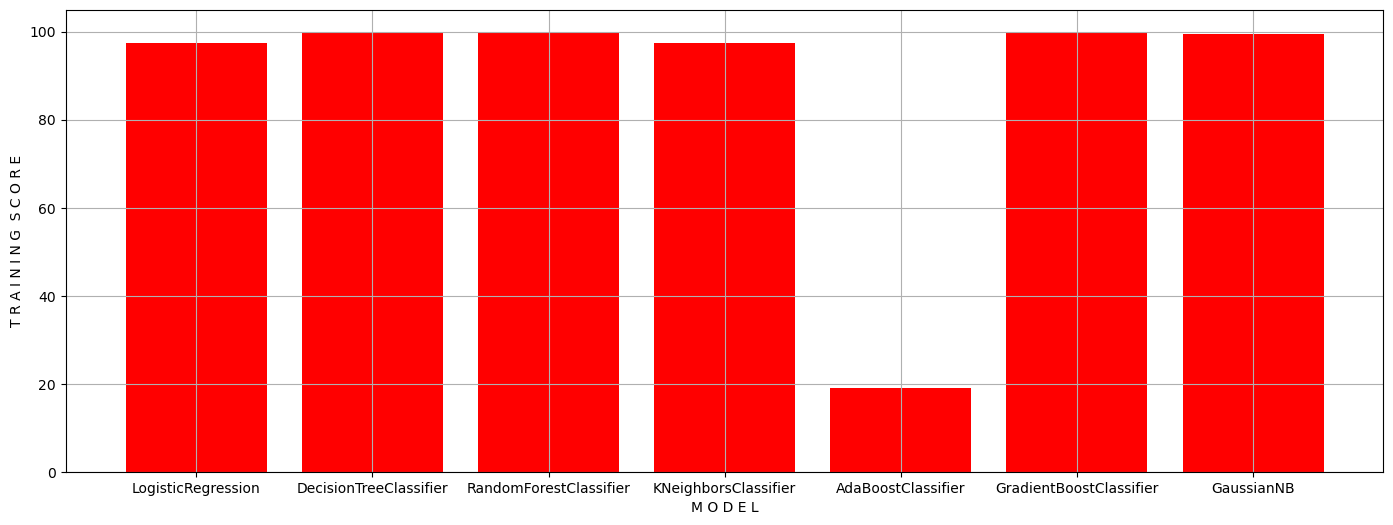

In [50]:
x = score.Model
y = score.TrainingScore
plt.figure(figsize = (17,6))
plt.bar(x,y, color = 'red')
plt.xlabel('M O D E L')
plt.ylabel('T R A I N I N G  S C O R E')
plt.grid(True)
plt.show()

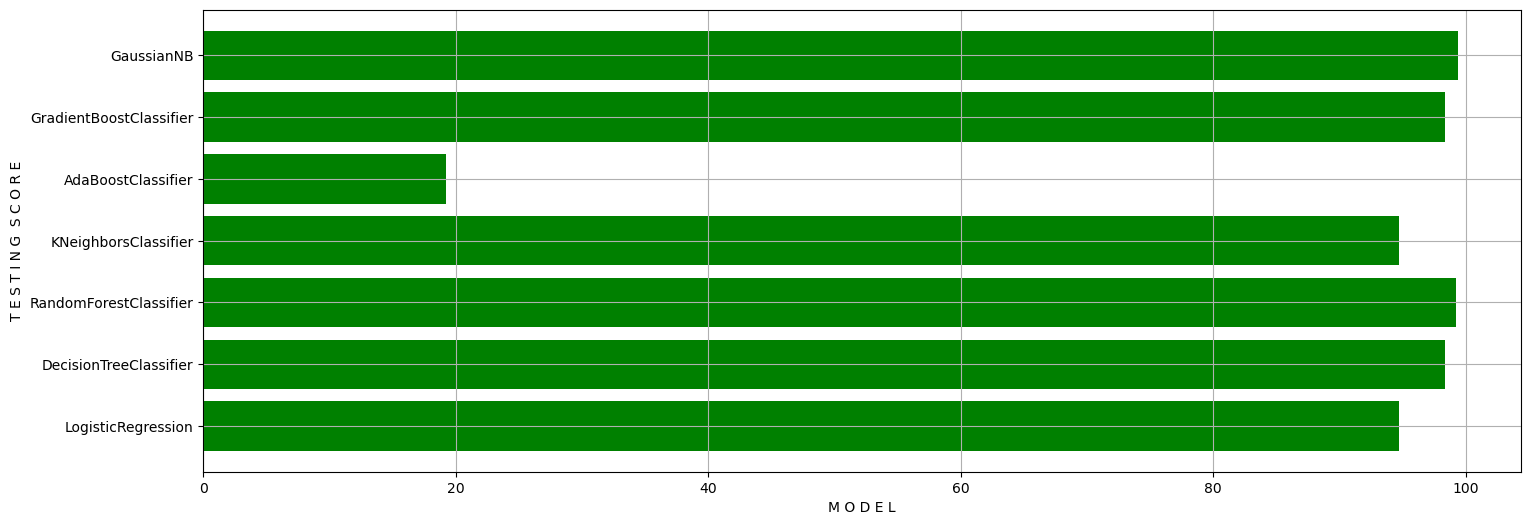

In [51]:
x = score.Model
y = score.TestingScore
plt.figure(figsize = (17,6))
plt.barh(x,y, color = 'green')
plt.xlabel('M O D E L')
plt.ylabel('T E S T I N G  S C O R E')
plt.grid(True)
plt.show()

## Build Gradio App

In [52]:
!pip3 install gradio

In [53]:
def fun(Nitrogen, Phosphorus, Potassium, Temperature, Humidity, pH_Value, Rainfall):
    pred = model3.predict([[Nitrogen, Phosphorus, Potassium, Temperature, Humidity, pH_Value, Rainfall]])
    return pred

In [54]:
import gradio as gr

In [56]:
headline = 'Crop Prediction App'
iface = gr.Interface(
    fn=fun,
    inputs=[
        gr.Textbox(label='Nitrogen'),
        gr.Textbox(label='Phosphorus'),
        gr.Textbox(label='Potassium'),
        gr.Textbox(label='Temperature'),
        gr.Textbox(label='Humidity'),
        gr.Textbox(label='pH_value'),
        gr.Textbox(label='Rainfall')
    ],
    outputs=gr.Textbox(label='Predicted Crop'),
    title=headline,
    css="""
    .gradio-container {
        background-color: #607456;
    }
    """
)

iface.launch(share=True)



* Running on local URL:  http://127.0.0.1:7863
* Running on public URL: https://0cb7e25993fb5b9d57.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
git init